In [2]:
from pathlib import Path
import json
import os
import random
import shutil

CURRENT_DIR = Path.cwd().resolve()
PROJECT_DIR = next(
    (folder for folder in [CURRENT_DIR, *CURRENT_DIR.parents]
     if (folder / "notebooks").is_dir() and (folder / "src").is_dir()),
    CURRENT_DIR
)

DATASET_DIR = PROJECT_DIR / "data" / "fashion_product_images_small"
DATASET_CSV = DATASET_DIR / "styles.csv"
IMAGE_DIR = DATASET_DIR / "images"
MODEL_DIR = PROJECT_DIR / "models" / "cv"
DAY7_MODEL_PATH = MODEL_DIR / "retailmind_transfer_learning.keras"
CLASS_NAMES_PATH = MODEL_DIR / "retailmind_transfer_classes.json"
REPORT_DIR = PROJECT_DIR / "reports" / "day11_image_augmentation"
CANDIDATE_DIR = REPORT_DIR / "candidates"
APPROVED_DIR = DATASET_DIR / "synthetic_train"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
CANDIDATE_DIR.mkdir(parents=True, exist_ok=True)

if not DATASET_CSV.is_file():
    raise FileNotFoundError(f"Fashion Product Images metadata not found: {DATASET_CSV}. Run the Day 7 dataset setup cell first.")
if not IMAGE_DIR.is_dir():
    raise FileNotFoundError(f"Fashion Product Images folder not found: {IMAGE_DIR}")
if not DAY7_MODEL_PATH.is_file():
    raise FileNotFoundError(f"Trained Day 7 classifier not found: {DAY7_MODEL_PATH}. Train Day 7 before running Day 11.")
if not CLASS_NAMES_PATH.is_file():
    raise FileNotFoundError(f"Day 7 category mapping not found: {CLASS_NAMES_PATH}. Run the final save cell in Day 7 first.")

print("Project folder:", PROJECT_DIR)
print("Fashion metadata:", DATASET_CSV)
print("Product images:", IMAGE_DIR)
print("Day 7 classifier:", DAY7_MODEL_PATH)

Project folder: C:\Users\rupam\OneDrive\Desktop\Retail_Mind
Fashion metadata: C:\Users\rupam\OneDrive\Desktop\Retail_Mind\data\fashion_product_images_small\styles.csv
Product images: C:\Users\rupam\OneDrive\Desktop\Retail_Mind\data\fashion_product_images_small\images
Day 7 classifier: C:\Users\rupam\OneDrive\Desktop\Retail_Mind\models\cv\retailmind_transfer_learning.keras


In [3]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

SEED = 42
LABEL_COLUMN = "subCategory"
CLASSIFIER_IMAGE_SIZE = (160, 160)
VAE_IMAGE_SIZE = (64, 64)
BATCH_SIZE = 32
VAE_EPOCHS = 12
VAE_LATENT_DIM = 128
MAX_VAE_IMAGES_PER_CLASS = 700
MAX_MINORITIES_TO_AUGMENT = 3
CANDIDATES_PER_CLASS = 48
AUGMENTED_EPOCHS = 6

np.random.seed(SEED)
random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE

print("TensorFlow:", tf.__version__)
print("Available devices:", tf.config.list_physical_devices())

TensorFlow: 2.22.0-rc0
Available devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [4]:
with CLASS_NAMES_PATH.open("r", encoding="utf-8") as file:
    class_names = json.load(file)

if not isinstance(class_names, list) or len(class_names) < 2:
    raise ValueError("The Day 7 class mapping is invalid. Check retailmind_transfer_classes.json.")

styles = pd.read_csv(DATASET_CSV, dtype={"id": "string"}, on_bad_lines="skip")
styles.columns = styles.columns.str.strip()

required_columns = {"id", LABEL_COLUMN}
missing_columns = required_columns.difference(styles.columns)
if missing_columns:
    raise ValueError(f"Missing columns in styles.csv: {sorted(missing_columns)}")

catalog = styles.dropna(subset=["id", LABEL_COLUMN]).copy()
catalog["id"] = catalog["id"].astype(str).str.strip().str.replace(r"\.0$", "", regex=True)
catalog[LABEL_COLUMN] = catalog[LABEL_COLUMN].astype(str).str.strip()
catalog = catalog[(catalog["id"] != "") & (catalog[LABEL_COLUMN] != "")]
catalog = catalog.drop_duplicates(subset="id")
catalog = catalog[catalog[LABEL_COLUMN].isin(class_names)].copy()
catalog["image_path"] = catalog["id"].map(lambda image_id: str(IMAGE_DIR / f"{image_id}.jpg"))
catalog = catalog[catalog["image_path"].map(os.path.isfile)].copy()

class_to_index = {name: index for index, name in enumerate(class_names)}
catalog["label_id"] = catalog[LABEL_COLUMN].map(class_to_index).astype("int32")
catalog = catalog.reset_index(drop=True)

missing_classes = sorted(set(class_names) - set(catalog[LABEL_COLUMN].unique()))
if missing_classes:
    raise ValueError(f"These Day 7 categories have no matching image files: {missing_classes}")

train_df, test_df = train_test_split(
    catalog,
    test_size=0.2,
    random_state=SEED,
    stratify=catalog["label_id"]
)
train_df, validation_df = train_test_split(
    train_df,
    test_size=0.1,
    random_state=SEED,
    stratify=train_df["label_id"]
)

train_df = train_df.reset_index(drop=True)
validation_df = validation_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Categories:", len(class_names))
print("Training images:", len(train_df))
print("Validation images:", len(validation_df))
print("Test images:", len(test_df))

Categories: 20
Training images: 30857
Validation images: 3429
Test images: 8572


In [5]:
def load_classifier_image(image_path, label):
    image_content = tf.io.read_file(image_path)
    image = tf.io.decode_image(image_content, channels=3, expand_animations=False)
    image = tf.image.resize(image, CLASSIFIER_IMAGE_SIZE)
    image.set_shape((CLASSIFIER_IMAGE_SIZE[0], CLASSIFIER_IMAGE_SIZE[1], 3))
    return image, tf.cast(label, tf.int32)


def create_classifier_dataset(frame, training=False):
    paths = frame["image_path"].astype(str).to_numpy()
    labels = frame["label_id"].to_numpy(dtype=np.int32)
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        dataset = dataset.shuffle(
            buffer_size=len(frame), seed=SEED, reshuffle_each_iteration=True
        )
    dataset = dataset.map(load_classifier_image, num_parallel_calls=AUTOTUNE)
    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)


validation_dataset = create_classifier_dataset(validation_df)
test_dataset = create_classifier_dataset(test_df)

baseline_model = tf.keras.models.load_model(DAY7_MODEL_PATH, compile=False)
output_count = int(baseline_model.output_shape[-1])
if output_count != len(class_names):
    raise ValueError(
        f"The Day 7 model predicts {output_count} classes but the saved mapping has {len(class_names)} categories."
    )

baseline_probabilities = baseline_model.predict(test_dataset, verbose=1)
y_test = test_df["label_id"].to_numpy(dtype=np.int32)
baseline_predictions = np.argmax(baseline_probabilities, axis=1)
baseline_report = classification_report(
    y_test,
    baseline_predictions,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

baseline_per_class = pd.DataFrame([
    {
        "category": category,
        "per_class_accuracy": baseline_report[category]["recall"],
        "precision": baseline_report[category]["precision"],
        "f1_score": baseline_report[category]["f1-score"],
        "support": int(baseline_report[category]["support"])
    }
    for category in class_names
])

baseline_accuracy = float(accuracy_score(y_test, baseline_predictions))
baseline_per_class.to_csv(REPORT_DIR / "per_class_metrics_before_augmentation.csv", index=False)

print(f"Day 7 baseline test accuracy: {baseline_accuracy:.4f}")
display(baseline_per_class.sort_values("per_class_accuracy"))

268/268 ━━━━━━━━━━━━━━━━━━━━ 160s 588ms/step
Day 7 baseline test accuracy: 0.9356


,category,per_class_accuracy,precision,f1_score,support
3,Dress,0.673684,0.528926,0.592593,95
13,Sandal,0.777202,0.572519,0.659341,193
9,Lips,0.800000,0.954545,0.870466,105
5,Flip Flops,0.825137,0.733010,0.776350,183
11,Makeup,0.852459,0.753623,0.800000,61
10,Loungewear and Nightwear,0.893617,0.506024,0.646154,94
2,Bottomwear,0.896104,0.975758,0.934236,539
15,Shoes,0.913547,0.979562,0.945403,1469
16,Socks,0.928058,0.941606,0.934783,139
18,Wallets,0.930481,0.896907,0.913386,187


In [6]:
training_counts = train_df[LABEL_COLUMN].value_counts().reindex(class_names, fill_value=0)
minority_categories = (
    training_counts.sort_values(ascending=True)
    .head(MAX_MINORITIES_TO_AUGMENT)
    .index.tolist()
)

count_summary = pd.DataFrame({
    "category": training_counts.index,
    "training_images": training_counts.values
}).sort_values("training_images", ascending=True)
count_summary["selected_for_augmentation"] = count_summary["category"].isin(minority_categories)

print("Underrepresented categories selected from the Day 7 training split:")
display(count_summary)
print("Categories to augment:", minority_categories)

Underrepresented categories selected from the Day 7 training split:


,category,training_images,selected_for_augmentation
11,Makeup,221,True
12,Nails,237,True
14,Saree,308,True
10,Loungewear and Nightwear,338,False
3,Dress,345,False
9,Lips,380,False
16,Socks,503,False
1,Belts,584,False
5,Flip Flops,657,False
18,Wallets,671,False


Categories to augment: ['Makeup', 'Nails', 'Saree']


In [7]:
class Sampling(tf.keras.layers.Layer):
    def call(self, inputs):
        mean, log_variance = inputs
        noise = tf.random.normal(shape=tf.shape(mean))
        return mean + tf.exp(0.5 * log_variance) * noise


def build_category_vae(latent_dim=VAE_LATENT_DIM):
    image_input = tf.keras.layers.Input(shape=(64, 64, 3))
    x = tf.keras.layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(image_input)
    x = tf.keras.layers.Conv2D(64, 3, strides=2, padding="same", activation="relu")(x)
    x = tf.keras.layers.Conv2D(128, 3, strides=2, padding="same", activation="relu")(x)
    x = tf.keras.layers.Conv2D(256, 3, strides=2, padding="same", activation="relu")(x)
    x = tf.keras.layers.Flatten()(x)
    x = tf.keras.layers.Dense(256, activation="relu")(x)
    mean = tf.keras.layers.Dense(latent_dim, name="latent_mean")(x)
    log_variance = tf.keras.layers.Dense(latent_dim, name="latent_log_variance")(x)
    sampled_latent = Sampling()([mean, log_variance])
    encoder = tf.keras.Model(image_input, [mean, log_variance, sampled_latent], name="category_encoder")

    latent_input = tf.keras.layers.Input(shape=(latent_dim,))
    x = tf.keras.layers.Dense(4 * 4 * 256, activation="relu")(latent_input)
    x = tf.keras.layers.Reshape((4, 4, 256))(x)
    x = tf.keras.layers.Conv2DTranspose(128, 3, strides=2, padding="same", activation="relu")(x)
    x = tf.keras.layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu")(x)
    x = tf.keras.layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu")(x)
    image_output = tf.keras.layers.Conv2DTranspose(3, 3, strides=2, padding="same", activation="tanh")(x)
    decoder = tf.keras.Model(latent_input, image_output, name="category_decoder")
    return encoder, decoder


def load_vae_image(image_path):
    image_content = tf.io.read_file(image_path)
    image = tf.io.decode_image(image_content, channels=3, expand_animations=False)
    image = tf.image.resize(image, VAE_IMAGE_SIZE)
    image = tf.cast(image, tf.float32) / 127.5 - 1.0
    image.set_shape((64, 64, 3))
    return image


def make_vae_dataset(frame):
    paths = frame["image_path"].astype(str).to_numpy()
    dataset = tf.data.Dataset.from_tensor_slices(paths)
    dataset = dataset.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    dataset = dataset.map(load_vae_image, num_parallel_calls=AUTOTUNE)
    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)


def make_vae_train_step(encoder, decoder, optimizer):
    @tf.function
    def train_step(images):
        with tf.GradientTape() as tape:
            mean, log_variance, sampled_latent = encoder(images, training=True)
            reconstructed = decoder(sampled_latent, training=True)
            reconstruction_loss = tf.reduce_mean(
                tf.reduce_sum(tf.square(images - reconstructed), axis=[1, 2, 3])
            )
            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(
                    1.0 + log_variance - tf.square(mean) - tf.exp(log_variance),
                    axis=1
                )
            )
            total_loss = reconstruction_loss + kl_loss
        variables = encoder.trainable_variables + decoder.trainable_variables
        gradients = tape.gradient(total_loss, variables)
        optimizer.apply_gradients(zip(gradients, variables))
        return total_loss, reconstruction_loss, kl_loss
    return train_step

Training category VAE 1/3: Makeup

Epoch 01/12 - loss: 9675.122
Epoch 02/12 - loss: 3641.433
Epoch 03/12 - loss: 1906.434
Epoch 04/12 - loss: 1749.961
Epoch 05/12 - loss: 1619.983
Epoch 06/12 - loss: 1499.331
Epoch 07/12 - loss: 1415.094
Epoch 08/12 - loss: 1285.940
Epoch 09/12 - loss: 1184.895
Epoch 10/12 - loss: 1128.930
Epoch 11/12 - loss: 1073.621
Epoch 12/12 - loss: 1052.704


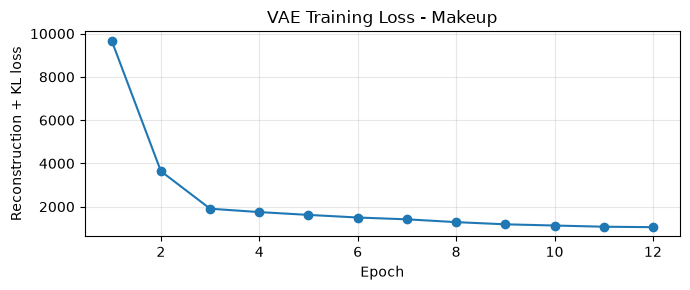

Training category VAE 2/3: Nails
Epoch 01/12 - loss: 10287.177
Epoch 02/12 - loss: 4469.226
Epoch 03/12 - loss: 1823.897
Epoch 04/12 - loss: 1610.322
Epoch 05/12 - loss: 1314.836
Epoch 06/12 - loss: 1100.861
Epoch 07/12 - loss: 930.370
Epoch 08/12 - loss: 863.280
Epoch 09/12 - loss: 837.426
Epoch 10/12 - loss: 803.816
Epoch 11/12 - loss: 786.200
Epoch 12/12 - loss: 771.993


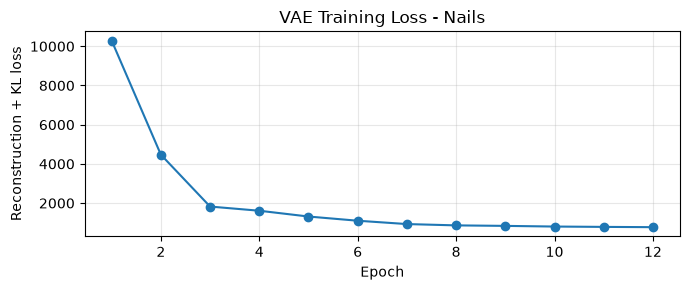

Training category VAE 3/3: Saree
Epoch 01/12 - loss: 8737.468
Epoch 02/12 - loss: 5278.007
Epoch 03/12 - loss: 2126.578
Epoch 04/12 - loss: 1720.269
Epoch 05/12 - loss: 1600.744
Epoch 06/12 - loss: 1543.283
Epoch 07/12 - loss: 1500.473
Epoch 08/12 - loss: 1458.188
Epoch 09/12 - loss: 1441.768
Epoch 10/12 - loss: 1398.234
Epoch 11/12 - loss: 1368.350
Epoch 12/12 - loss: 1358.193


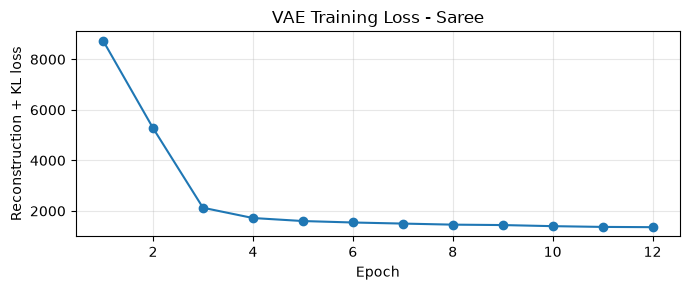

In [8]:
trained_decoders = {}
vae_training_history = {}

for category_number, category in enumerate(minority_categories, start=1):
    category_frame = train_df[train_df[LABEL_COLUMN] == category].copy()
    if len(category_frame) > MAX_VAE_IMAGES_PER_CLASS:
        category_frame = category_frame.sample(
            n=MAX_VAE_IMAGES_PER_CLASS, random_state=SEED
        )

    if len(category_frame) < 50:
        print(f"Skipping {category}: only {len(category_frame)} training images are available.")
        continue

    print(f"Training category VAE {category_number}/{len(minority_categories)}: {category}")
    vae_dataset = make_vae_dataset(category_frame)
    encoder, decoder = build_category_vae()
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
    train_step = make_vae_train_step(encoder, decoder, optimizer)
    epoch_losses = []

    for epoch in range(VAE_EPOCHS):
        batch_losses = []
        for image_batch in vae_dataset:
            total_loss, reconstruction_loss, kl_loss = train_step(image_batch)
            batch_losses.append(float(total_loss.numpy()))
        mean_epoch_loss = float(np.mean(batch_losses))
        epoch_losses.append(mean_epoch_loss)
        print(f"Epoch {epoch + 1:02d}/{VAE_EPOCHS} - loss: {mean_epoch_loss:.3f}")

    trained_decoders[category] = decoder
    vae_training_history[category] = epoch_losses

    plt.figure(figsize=(7, 3))
    plt.plot(range(1, len(epoch_losses) + 1), epoch_losses, marker="o")
    plt.title(f"VAE Training Loss - {category}")
    plt.xlabel("Epoch")
    plt.ylabel("Reconstruction + KL loss")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(REPORT_DIR / f"vae_loss_{category_number}.png", dpi=140)
    plt.show()

if not trained_decoders:
    raise RuntimeError("No category VAE was trained. Check the selected categories and available training images.")

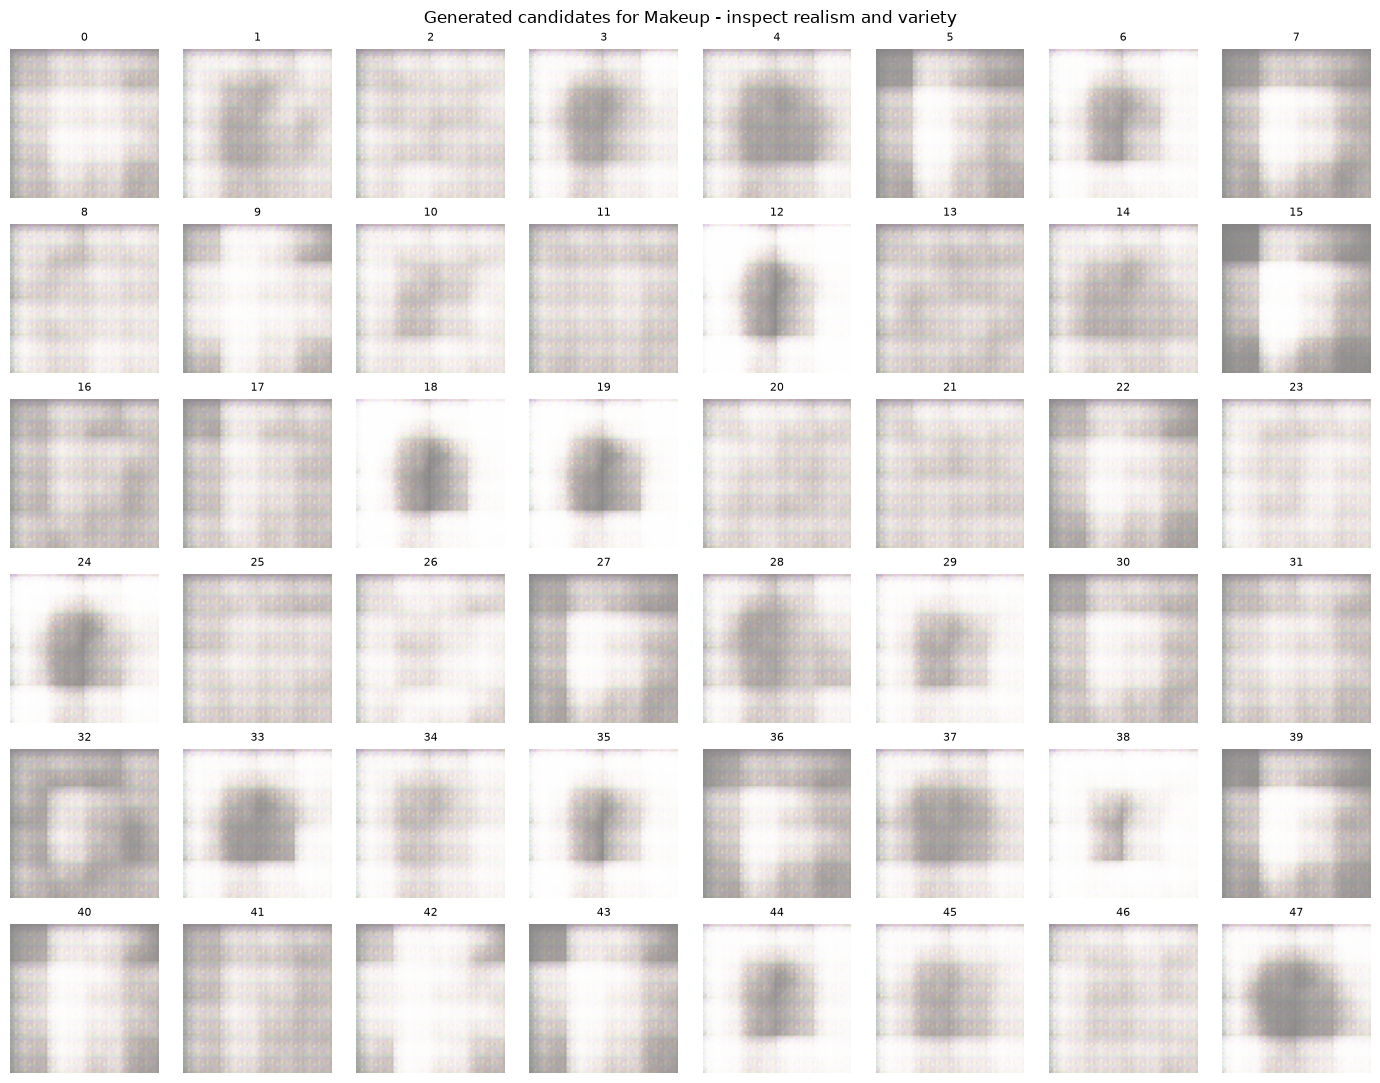

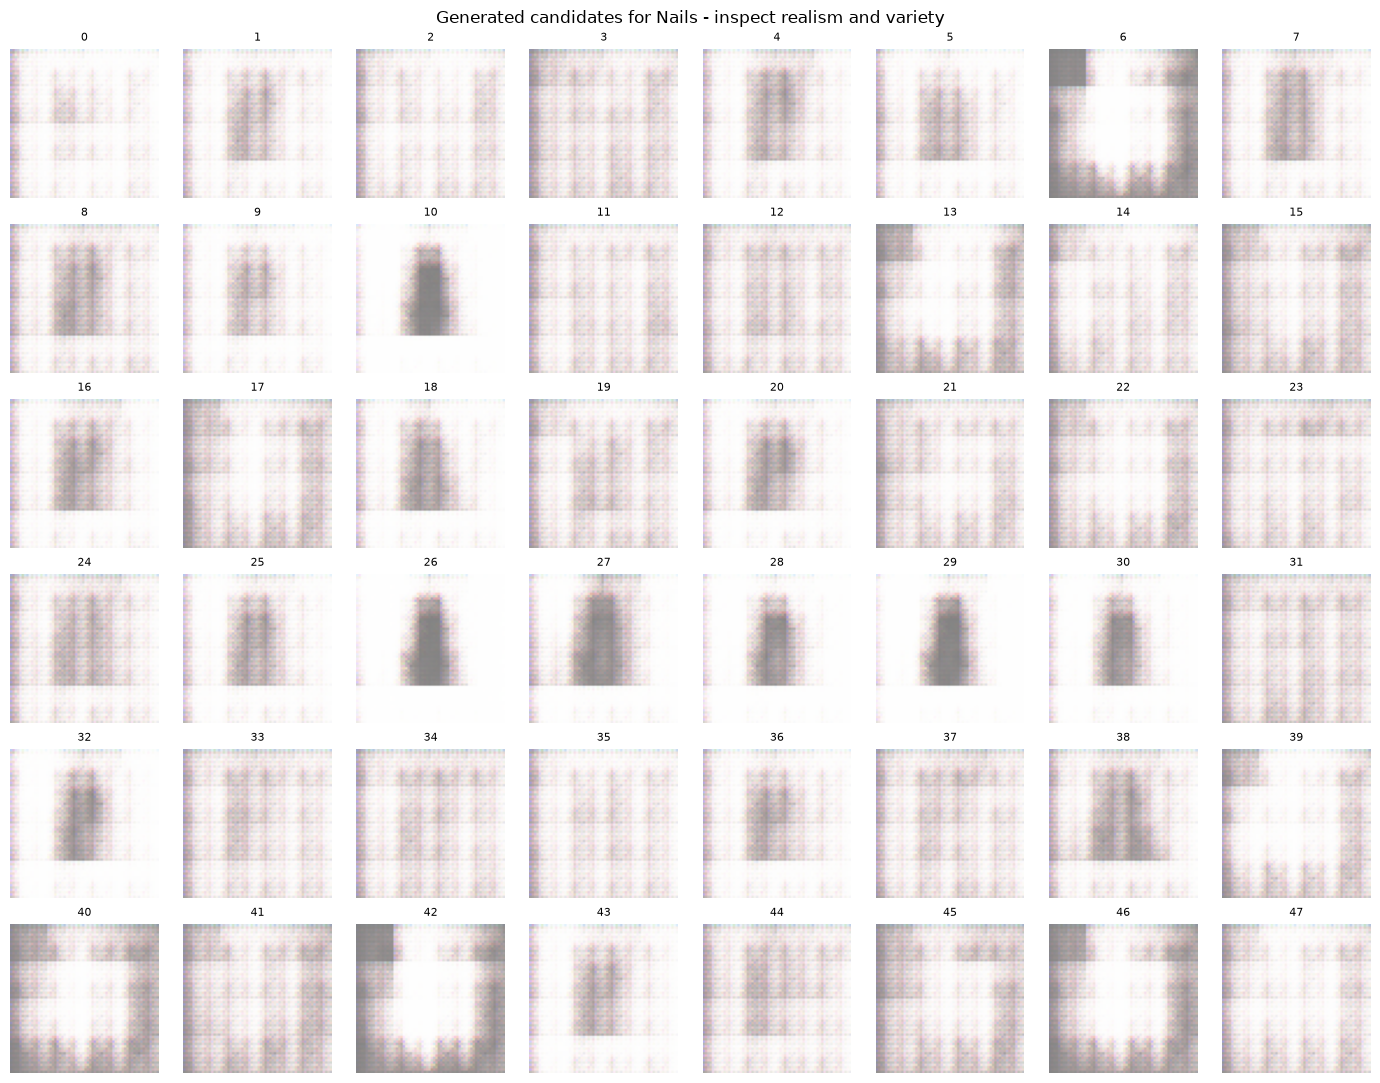

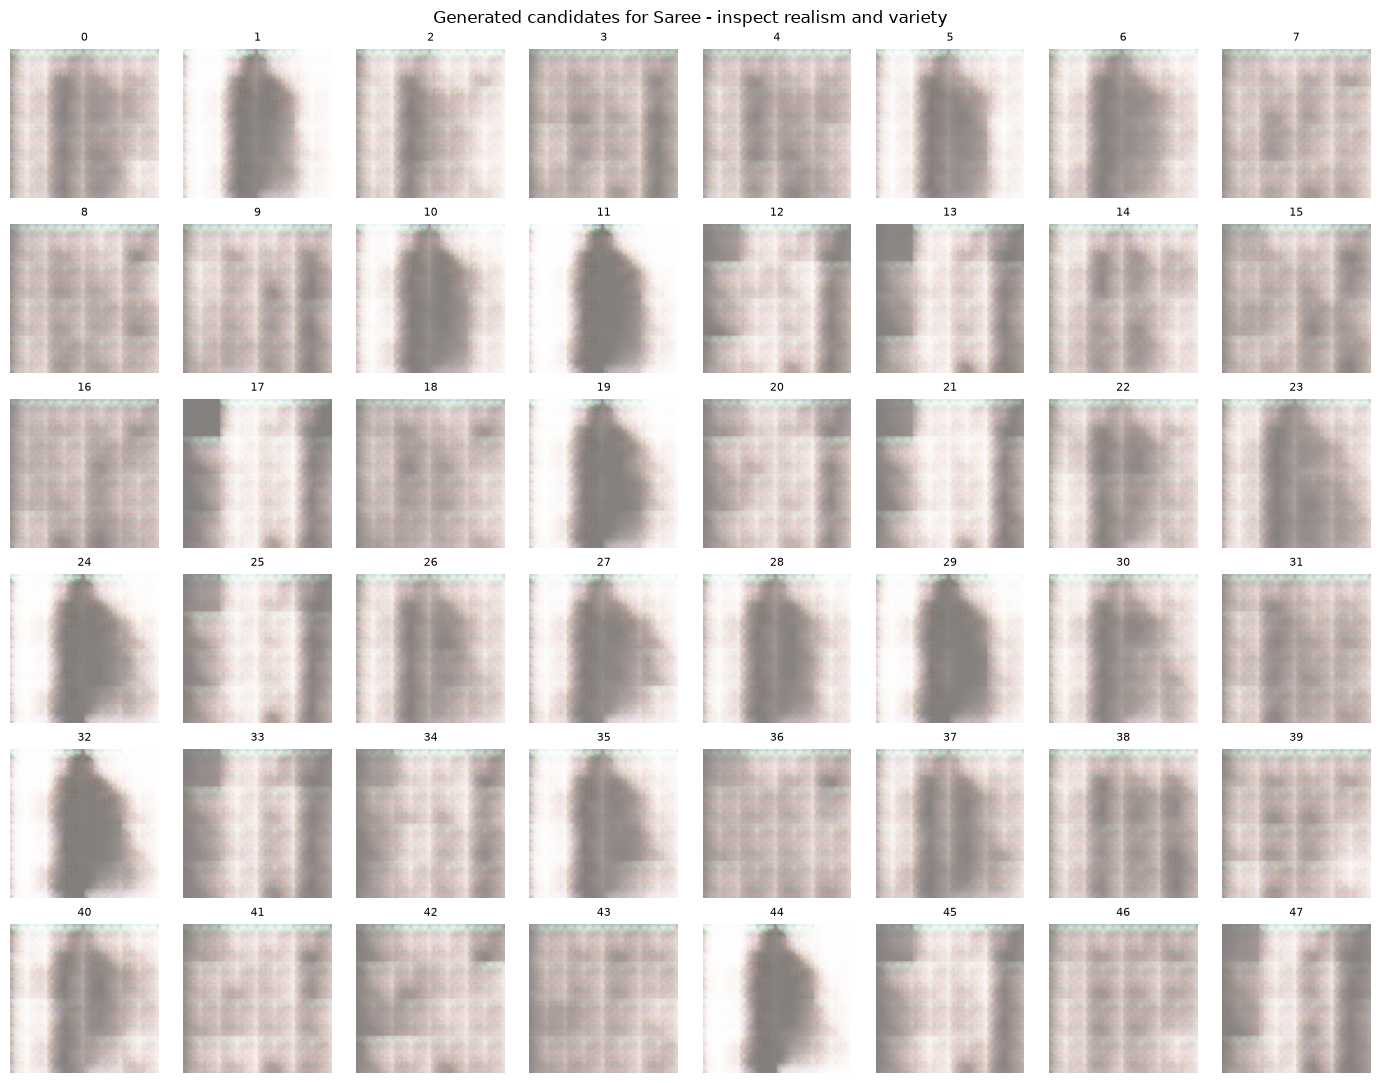

Mean pairwise pixel distance (higher usually indicates more visual variation):
Makeup: 0.1124
Nails: 0.0867
Saree: 0.1360
Candidate image folders: C:\Users\rupam\OneDrive\Desktop\Retail_Mind\reports\day11_image_augmentation\candidates


In [9]:
candidate_paths = {}
candidate_diversity = {}

for category, decoder in trained_decoders.items():
    category_folder = CANDIDATE_DIR / category.replace("/", "_")
    category_folder.mkdir(parents=True, exist_ok=True)
    generated_images = []
    generated_paths = []

    latent_vectors = tf.random.normal((CANDIDATES_PER_CLASS, VAE_LATENT_DIM))
    generated_batch = decoder.predict(latent_vectors, verbose=0)

    for candidate_index, generated_image in enumerate(generated_batch):
        image_array = np.clip((generated_image + 1.0) * 127.5, 0, 255).astype(np.uint8)
        image_path = category_folder / f"candidate_{candidate_index:03d}.png"
        tf.io.write_file(str(image_path), tf.io.encode_png(image_array))
        generated_images.append(image_array)
        generated_paths.append(image_path)

    generated_images_array = np.asarray(generated_images, dtype=np.float32) / 255.0
    flattened = generated_images_array.reshape(len(generated_images_array), -1)
    if len(flattened) > 1:
        distances = np.mean(np.abs(flattened[:, None, :] - flattened[None, :, :]), axis=2)
        upper_triangle = distances[np.triu_indices(len(flattened), k=1)]
        mean_pairwise_distance = float(np.mean(upper_triangle))
    else:
        mean_pairwise_distance = 0.0

    candidate_paths[category] = generated_paths
    candidate_diversity[category] = mean_pairwise_distance

    figure, axes = plt.subplots(6, 8, figsize=(14, 11))
    for index, axis in enumerate(axes.flat):
        if index < len(generated_images):
            axis.imshow(generated_images[index])
            axis.set_title(str(index), fontsize=8)
        axis.axis("off")
    figure.suptitle(f"Generated candidates for {category} - inspect realism and variety")
    plt.tight_layout()
    plt.savefig(REPORT_DIR / f"generated_candidates_{category.replace('/', '_')}.png", dpi=150)
    plt.show()

print("Mean pairwise pixel distance (higher usually indicates more visual variation):")
for category, distance in candidate_diversity.items():
    print(f"{category}: {distance:.4f}")
print("Candidate image folders:", CANDIDATE_DIR)

In [10]:
APPROVED_SYNTHETIC_INDICES = {
    category: [] for category in trained_decoders
}

print("Review the generated candidate grids from the previous cell.")
print("For each category, enter only the image indexes that look realistic and match the category.")
print("Example: APPROVED_SYNTHETIC_INDICES['Tshirts'] = [1, 4, 8, 13]")
print("Leave weak, blurry, repeated, or incorrect images out of the list.")
display(pd.DataFrame({
    "category": list(candidate_paths.keys()),
    "candidate_images": [len(paths) for paths in candidate_paths.values()],
    "mean_pairwise_pixel_distance": [candidate_diversity[name] for name in candidate_paths]
}))

Review the generated candidate grids from the previous cell.
For each category, enter only the image indexes that look realistic and match the category.
Example: APPROVED_SYNTHETIC_INDICES['Tshirts'] = [1, 4, 8, 13]
Leave weak, blurry, repeated, or incorrect images out of the list.


,category,candidate_images,mean_pairwise_pixel_distance
0,Makeup,48,0.112421
1,Nails,48,0.086651
2,Saree,48,0.135979


In [11]:
synthetic_records = []

for category, approved_indices in APPROVED_SYNTHETIC_INDICES.items():
    if category not in candidate_paths:
        continue

    unique_indices = sorted(set(int(index) for index in approved_indices))
    for index in unique_indices:
        if index < 0 or index >= len(candidate_paths[category]):
            raise IndexError(f"Candidate index {index} is out of range for category {category}.")

    category_folder = APPROVED_DIR / category.replace("/", "_")
    category_folder.mkdir(parents=True, exist_ok=True)

    for index in unique_indices:
        source_path = candidate_paths[category][index]
        destination_path = category_folder / f"approved_{index:03d}.png"
        shutil.copy2(source_path, destination_path)
        synthetic_records.append({
            "image_path": str(destination_path),
            "label_id": int(class_to_index[category]),
            LABEL_COLUMN: category,
            "source": "VAE synthetic"
        })

synthetic_df = pd.DataFrame(synthetic_records)
if synthetic_df.empty:
    print("No synthetic images were approved yet.")
    print("Edit APPROVED_SYNTHETIC_INDICES in the previous cell after reviewing the candidate grids, then rerun this and the following cells.")
else:
    synthetic_df.to_csv(REPORT_DIR / "approved_synthetic_images.csv", index=False)
    print("Approved synthetic images:", len(synthetic_df))
    display(synthetic_df.groupby(LABEL_COLUMN).size().rename("approved_images").to_frame())

No synthetic images were approved yet.
Edit APPROVED_SYNTHETIC_INDICES in the previous cell after reviewing the candidate grids, then rerun this and the following cells.


In [12]:
augmented_model = None
augmented_training_df = None

if synthetic_df.empty:
    print("Classifier fine-tuning skipped because no synthetic images were approved.")
    print("After selecting realistic candidates, rerun the approval cell and continue from here.")
else:
    augmented_training_df = pd.concat([
        train_df[["image_path", "label_id"]],
        synthetic_df[["image_path", "label_id"]]
    ], ignore_index=True)

    augmented_training_dataset = create_classifier_dataset(
        augmented_training_df,
        training=True
    )

    augmented_model = tf.keras.models.load_model(DAY7_MODEL_PATH, compile=False)
    for layer in augmented_model.layers:
        if isinstance(layer, tf.keras.Model) and "mobilenetv2" in layer.name.lower():
            layer.trainable = False

    augmented_model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.00002),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    augmented_callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_accuracy", patience=2, restore_best_weights=True
        )
    ]

    augmented_history = augmented_model.fit(
        augmented_training_dataset,
        validation_data=validation_dataset,
        epochs=AUGMENTED_EPOCHS,
        callbacks=augmented_callbacks,
        verbose=1
    )

Classifier fine-tuning skipped because no synthetic images were approved.
After selecting realistic candidates, rerun the approval cell and continue from here.


In [13]:
if augmented_model is None:
    print("No post-augmentation evaluation is available until realistic synthetic images are approved and the classifier is fine-tuned.")
else:
    augmented_probabilities = augmented_model.predict(test_dataset, verbose=1)
    augmented_predictions = np.argmax(augmented_probabilities, axis=1)
    augmented_report = classification_report(
        y_test,
        augmented_predictions,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    augmented_per_class = pd.DataFrame([
        {
            "category": category,
            "per_class_accuracy": augmented_report[category]["recall"],
            "precision": augmented_report[category]["precision"],
            "f1_score": augmented_report[category]["f1-score"],
            "support": int(augmented_report[category]["support"])
        }
        for category in class_names
    ])

    comparison = baseline_per_class.merge(
        augmented_per_class,
        on="category",
        suffixes=("_before", "_after")
    )
    comparison["accuracy_lift_percentage_points"] = (
        comparison["per_class_accuracy_after"] - comparison["per_class_accuracy_before"]
    ) * 100
    comparison.to_csv(REPORT_DIR / "per_class_metrics_before_after.csv", index=False)

    augmented_accuracy = float(accuracy_score(y_test, augmented_predictions))
    baseline_gap = float(
        baseline_per_class["per_class_accuracy"].max()
        - baseline_per_class["per_class_accuracy"].min()
    )
    augmented_gap = float(
        augmented_per_class["per_class_accuracy"].max()
        - augmented_per_class["per_class_accuracy"].min()
    )

    print(f"Day 7 baseline accuracy: {baseline_accuracy:.4f}")
    print(f"After VAE augmentation accuracy: {augmented_accuracy:.4f}")
    print(f"Overall accuracy change: {augmented_accuracy - baseline_accuracy:+.4f}")
    print(f"Per-class recall gap before augmentation: {baseline_gap:.4f}")
    print(f"Per-class recall gap after augmentation: {augmented_gap:.4f}")
    display(comparison.sort_values("accuracy_lift_percentage_points"))

    figure, axis = plt.subplots(figsize=(13, 6))
    positions = np.arange(len(class_names))
    width = 0.38
    axis.bar(
        positions - width / 2,
        comparison["per_class_accuracy_before"],
        width,
        label="Day 7 - before augmentation"
    )
    axis.bar(
        positions + width / 2,
        comparison["per_class_accuracy_after"],
        width,
        label="After VAE augmentation"
    )
    axis.set_xticks(positions)
    axis.set_xticklabels(class_names, rotation=75, ha="right")
    axis.set_ylabel("Per-class accuracy (recall)")
    axis.set_title("Per-class accuracy before and after image augmentation")
    axis.legend()
    axis.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.savefig(REPORT_DIR / "per_class_accuracy_comparison.png", dpi=150)
    plt.show()

No post-augmentation evaluation is available until realistic synthetic images are approved and the classifier is fine-tuned.


In [14]:
if augmented_model is not None:
    augmented_model_path = MODEL_DIR / "retailmind_transfer_learning_augmented.keras"
    augmented_model.save(augmented_model_path)

    augmented_metrics = {
        "project": "RetailMind AI",
        "module": "Day 11 - VAE Image Augmentation",
        "base_classifier": str(DAY7_MODEL_PATH.relative_to(PROJECT_DIR)),
        "augmented_classifier": str(augmented_model_path.relative_to(PROJECT_DIR)),
        "generator": "Category-specific Variational Autoencoder",
        "label_column": LABEL_COLUMN,
        "class_names": class_names,
        "minority_categories": minority_categories,
        "approved_synthetic_images": int(len(synthetic_df)),
        "approved_synthetic_by_category": {
            str(category): int(count)
            for category, count in synthetic_df.groupby(LABEL_COLUMN).size().items()
        },
        "test_accuracy_before": baseline_accuracy,
        "test_accuracy_after": augmented_accuracy,
        "accuracy_change": augmented_accuracy - baseline_accuracy,
        "per_class_recall_gap_before": baseline_gap,
        "per_class_recall_gap_after": augmented_gap,
        "per_class_metrics_file": str((REPORT_DIR / "per_class_metrics_before_after.csv").relative_to(PROJECT_DIR))
    }

    with (REPORT_DIR / "metrics.json").open("w", encoding="utf-8") as file:
        json.dump(augmented_metrics, file, indent=4)

    print("Augmented classifier saved:", augmented_model_path)
    print("Day 11 metrics saved:", REPORT_DIR / "metrics.json")
    print("Per-class comparison saved:", REPORT_DIR / "per_class_metrics_before_after.csv")
    print("The original Day 7 model was kept unchanged.")
else:
    print("No augmented classifier was saved. Approve realistic synthetic candidates and rerun the final cells.")

No augmented classifier was saved. Approve realistic synthetic candidates and rerun the final cells.


In [15]:
print("Day 11 image augmentation workflow finished.")
print("Day 7 classifier:", DAY7_MODEL_PATH)
print("Candidate images:", CANDIDATE_DIR)
print("Approved images:", len(synthetic_records))
if augmented_model is not None:
    print("Augmented classifier:", MODEL_DIR / "retailmind_transfer_learning_augmented.keras")
    print("Per-class evaluation:", REPORT_DIR / "per_class_metrics_before_after.csv")
else:
    print("Next step: inspect candidate grids, fill APPROVED_SYNTHETIC_INDICES, and rerun the approval and classifier cells.")

Day 11 image augmentation workflow finished.
Day 7 classifier: C:\Users\rupam\OneDrive\Desktop\Retail_Mind\models\cv\retailmind_transfer_learning.keras
Candidate images: C:\Users\rupam\OneDrive\Desktop\Retail_Mind\reports\day11_image_augmentation\candidates
Approved images: 0
Next step: inspect candidate grids, fill APPROVED_SYNTHETIC_INDICES, and rerun the approval and classifier cells.
